# EDA – Fresh vs Rotten Apples
Dataset: `./dataset/{Train,Test}/{freshapples,rottenapples}`

## 1. Import thư viện & cấu hình

In [18]:
from pathlib import Path
import hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from PIL import Image, ImageFile

warnings.filterwarnings('ignore')
ImageFile.LOAD_TRUNCATED_IMAGES = False
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True,
                      'grid.alpha': .3, 'font.size': 10})

DATASET_DIR = Path('dataset')
OUTPUT_DIR  = Path('eda_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
EXT = {'.jpg','.jpeg','.png','.bmp','.gif','.tif','.tiff','.webp'}
COLORS = {'freshapples':'#66c2a5', 'rottenapples':'#fc8d62'}

assert DATASET_DIR.exists(), f'Dataset not found: {DATASET_DIR}'
print('Setup OK')

Setup OK


## 2. Quét ảnh & thu thập metadata
Duyệt toàn bộ file ảnh, đọc kích thước, mode, format, tính MD5 và đánh dấu ảnh hỏng.

In [11]:
paths = sorted(p for p in DATASET_DIR.rglob('*')
               if p.is_file() and p.suffix.lower() in EXT)
print(f'Tìm thấy {len(paths):,} file ảnh')

def parse_split_class(p):
    parts = p.relative_to(DATASET_DIR).parts
    return (parts[0], parts[1]) if len(parts) > 2 else ('unknown','unknown')

rows = []
for i, p in enumerate(paths):
    sp, cls = parse_split_class(p)
    r = dict(path=str(p), filename=p.name, split=sp, label=cls,
             ext=p.suffix.lower(), size_kb=p.stat().st_size/1024,
             w=np.nan, h=np.nan, ch=np.nan, mode=None, fmt=None,
             valid=False, error=None, md5=None)
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            r.update(w=im.width, h=im.height, mode=im.mode,
                     fmt=im.format, ch=len(im.getbands()), valid=True)
        r['md5'] = hashlib.md5(p.read_bytes()).hexdigest()
    except Exception as e:
        r['error'] = f'{type(e).__name__}: {e}'
    rows.append(r)
    if (i+1) % 2000 == 0:
        print(f'  {i+1}/{len(paths)}')

df = pd.DataFrame(rows)
df['ratio'] = df.w / df.h
df['mpx']   = df.w * df.h / 1e6
ok = df[df.valid].copy()
df.to_csv(OUTPUT_DIR/'metadata.csv', index=False)

print(f'\nTổng: {len(df):,} | Hợp lệ: {len(ok):,} | Lỗi: {len(df)-len(ok):,}')
display(df.head())
if (~df.valid).any():
    display(df.loc[~df.valid, ['filename','error']])

Tìm thấy 7,451 file ảnh
  2000/7451
  4000/7451
  6000/7451

Tổng: 7,451 | Hợp lệ: 7,451 | Lỗi: 0


,path,filename,split,label,ext,size_kb,w,h,ch,mode,fmt,valid,error,md5,ratio,mpx
0,dataset\Test\freshapples\a_f001.png,a_f001.png,Test,freshapples,.png,122.964844,470,386,3,RGB,PNG,True,None,828d4a5ebb15717f1de62884d1ea85a0,1.217617,0.181420
1,dataset\Test\freshapples\a_f002.png,a_f002.png,Test,freshapples,.png,130.358398,372,398,3,RGB,PNG,True,None,ba3254817f54fbae6903a84e5d0db87a,0.934673,0.148056
2,dataset\Test\freshapples\a_f003.png,a_f003.png,Test,freshapples,.png,132.312500,414,420,3,RGB,PNG,True,None,24bc4e197dca8a1700b2c2faf8f6e4d3,0.985714,0.173880
3,dataset\Test\freshapples\a_f004.png,a_f004.png,Test,freshapples,.png,117.511719,382,422,3,RGB,PNG,True,None,e6847044c22101d3c4e313a55f369ff7,0.905213,0.161204
4,dataset\Test\freshapples\a_f005.png,a_f005.png,Test,freshapples,.png,116.089844,360,366,3,RGB,PNG,True,None,8905193b10a2005d0a83af47e276c684,0.983607,0.131760


## 3. Phân bố lớp & tỷ lệ Train/Test
Kiểm tra số lượng ảnh mỗi lớp, mức độ mất cân bằng, và cách chia Train/Test.

label,freshapples,rottenapples
split,,
Test,791,988
Train,2424,3248


Số lớp: 2 | Imbalance ratio: 1.32


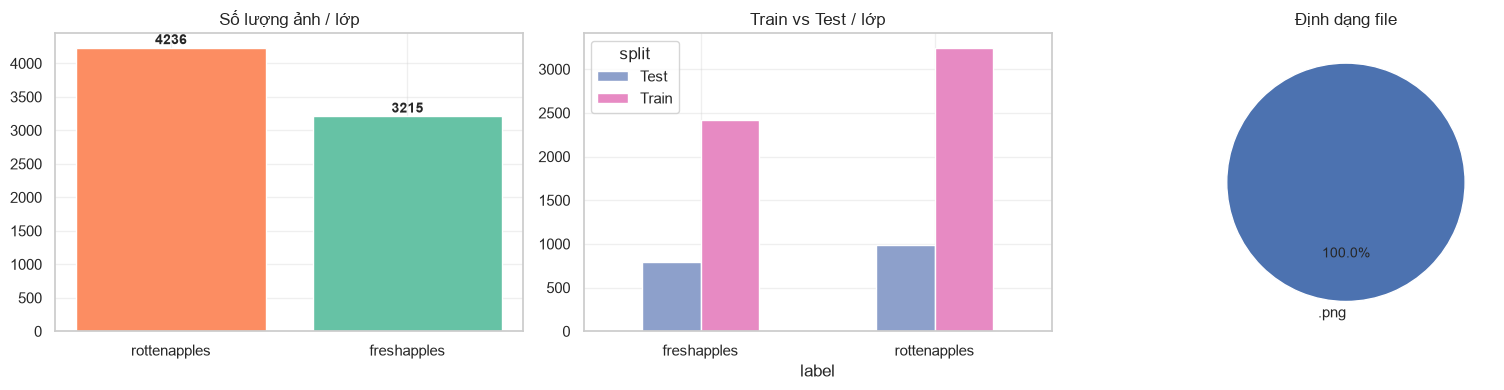

In [12]:
ct = df.groupby(['split','label']).size().unstack(fill_value=0)
display(ct)

totals = df.label.value_counts()
imbalance = totals.max() / totals.min()
print(f'Số lớp: {len(totals)} | Imbalance ratio: {imbalance:.2f}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].bar(totals.index, totals.values,
            color=[COLORS.get(c,'#888') for c in totals.index])
for i,v in enumerate(totals.values):
    axes[0].text(i, v+50, str(v), ha='center', fontweight='bold')
axes[0].set_title('Số lượng ảnh / lớp')
axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))

ct.T.plot.bar(ax=axes[1], color=['#8da0cb','#e78ac3'])
axes[1].set_title('Train vs Test / lớp')
axes[1].tick_params(axis='x', rotation=0)

ext_ct = df.ext.value_counts()
axes[2].pie(ext_ct, labels=ext_ct.index, autopct='%.1f%%', startangle=90)
axes[2].set_title('Định dạng file')

plt.tight_layout()
fig.savefig(OUTPUT_DIR/'class_balance.png', bbox_inches='tight')
plt.show()
ct.to_csv(OUTPUT_DIR/'class_counts.csv')

## 4. Thống kê kích thước & dung lượng ảnh
Phân bố width, height, aspect ratio, file size theo từng lớp.

,count,mean,std,min,25%,50%,75%,max
w,7451.0,355.17,87.17,150.00,302.00,374.00,412.00,588.00
h,7451.0,339.99,81.94,142.00,294.00,358.00,400.00,510.00
ratio,7451.0,1.05,0.10,0.79,0.98,1.05,1.12,1.39
mpx,7451.0,0.13,0.05,0.02,0.09,0.14,0.16,0.30
size_kb,7451.0,124.36,56.27,17.92,81.53,125.73,156.67,366.90


w                        h                     ratio         \
              min median    mean  max  min median    mean  max   min median   
label                                                                         
freshapples   150  366.0  332.68  584  142  360.0  329.82  510  0.79   1.01   
rottenapples  182  382.0  372.24  588  192  358.0  347.71  492  0.82   1.07   

                           mpx                    size_kb                  \
              mean   max   min median  mean   max     min  median    mean   
label                                                                       
freshapples   1.02  1.39  0.02   0.13  0.12  0.30   17.92  118.47  110.74   
rottenapples  1.07  1.38  0.03   0.14  0.13  0.26   28.62  137.00  134.70   

                      
                 max  
label                 
freshapples   320.17  
rottenapples  366.90

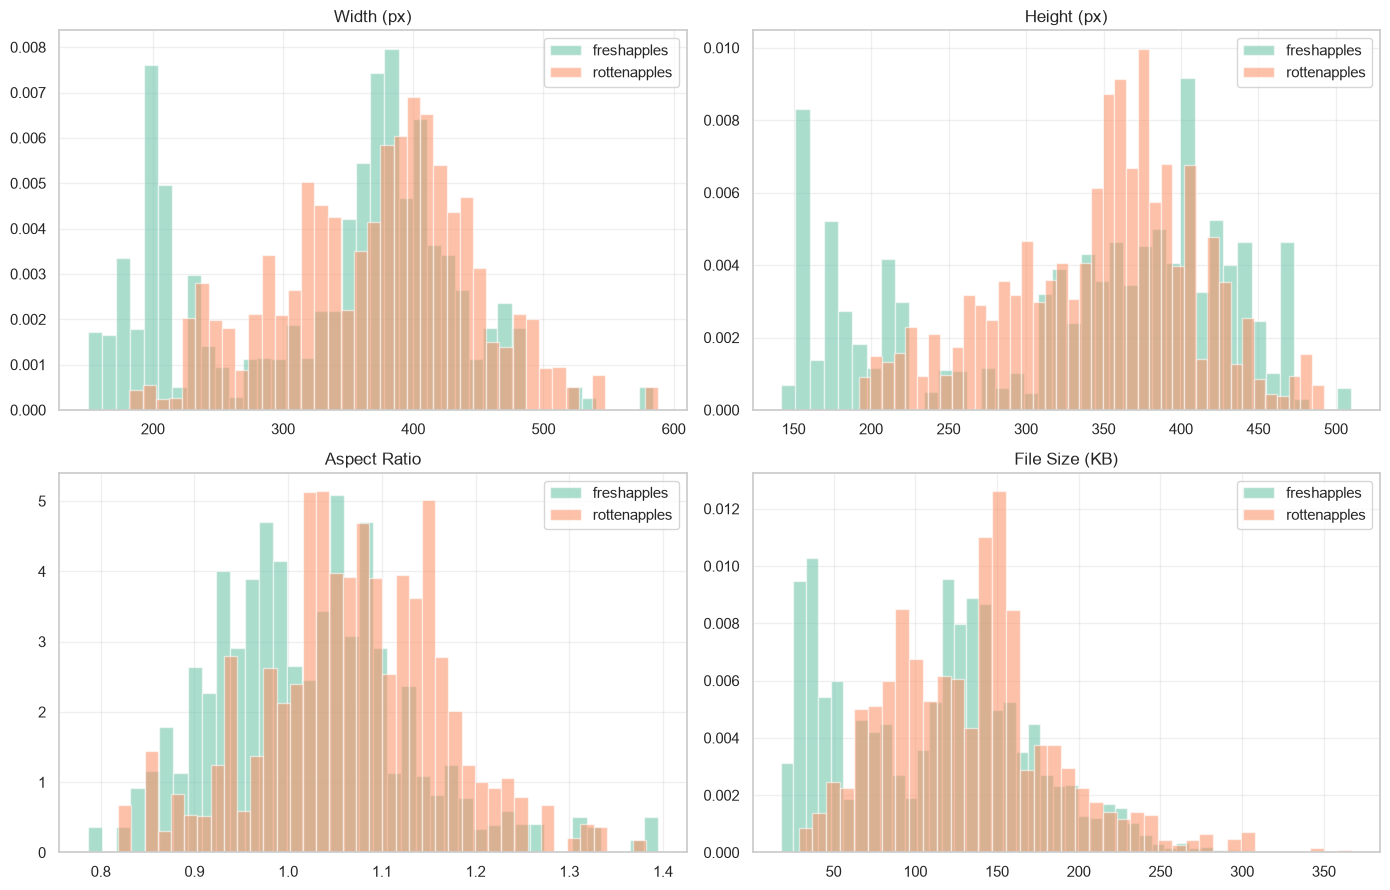

In [13]:
stats_cols = ['w','h','ratio','mpx','size_kb']
display(ok[stats_cols].describe().T.round(2))

summary = ok.groupby('label')[stats_cols].agg(['min','median','mean','max'])
display(summary.round(2))
summary.to_csv(OUTPUT_DIR/'size_summary.csv')

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
titles = ['Width (px)','Height (px)','Aspect Ratio','File Size (KB)']
for ax, col, title in zip(axes.ravel(), stats_cols[:3]+['size_kb'], titles):
    for lbl, grp in ok.groupby('label'):
        ax.hist(grp[col], bins=40, alpha=.55, label=lbl,
                color=COLORS.get(lbl,'#888'), density=True)
    ax.set_title(title); ax.legend()
plt.tight_layout()
fig.savefig(OUTPUT_DIR/'size_distributions.png', bbox_inches='tight')
plt.show()

## 5. Phát hiện ảnh trùng lặp (MD5)
Tìm các file có cùng hash MD5 — ảnh trùng có thể gây data leakage giữa Train và Test.

In [14]:
dups = ok[ok.duplicated('md5', keep=False)].sort_values('md5')
print(f'Ảnh trùng MD5: {dups.md5.nunique()} nhóm, {len(dups)} file')
if len(dups):
    display(dups[['label','split','filename','md5']].head(20))
    dups.to_csv(OUTPUT_DIR/'duplicates.csv', index=False)

Ảnh trùng MD5: 1637 nhóm, 4057 file


,label,split,filename,md5
3495,freshapples,Train,saltandpepper_Screen Shot 2018-06-08 at 5.06.1...,000c54bbfcbd4de02ec85abfc366db90
2203,freshapples,Train,a_f425.png,000c54bbfcbd4de02ec85abfc366db90
2387,freshapples,Train,a_f609.png,0012eebbf30111d46bcc15645002b19e
3959,freshapples,Train,translation_Screen Shot 2018-06-08 at 5.22.35 ...,0012eebbf30111d46bcc15645002b19e
1850,freshapples,Train,a_f072.png,002206d50847cc61b72c071f45a39fef
2661,freshapples,Train,rotated_by_15_Screen Shot 2018-06-08 at 5.25.2...,002206d50847cc61b72c071f45a39fef
41,freshapples,Test,a_f042.png,002206d50847cc61b72c071f45a39fef
913,rottenapples,Test,a_r123.png,0034fafefbd77d58602beb7be22170b7
4400,rottenapples,Train,a_r198.png,0034fafefbd77d58602beb7be22170b7
5625,rottenapples,Train,rotated_by_30_Screen Shot 2018-06-08 at 2.51.2...,0034fafefbd77d58602beb7be22170b7


## 6. Trích xuất đặc trưng pixel (resize 128×128)
Tính brightness, contrast, saturation, mean RGB, tỷ lệ pixel tối/sáng cho mỗi ảnh.

In [15]:
def px_feat(path):
    with Image.open(path) as im:
        a = np.asarray(im.convert('RGB').resize((128,128)), np.float32)/255
    g = a.mean(axis=2)
    return dict(
        brightness=g.mean(), contrast=g.std(),
        R=a[:,:,0].mean(), G=a[:,:,1].mean(), B=a[:,:,2].mean(),
        saturation=(a.max(2)-a.min(2)).mean(),
        dark_frac=(g<.2).mean(), bright_frac=(g>.8).mean())

feats = pd.DataFrame([px_feat(p) for p in ok.path], index=ok.index)
ok = pd.concat([ok, feats], axis=1)
ok.to_csv(OUTPUT_DIR/'valid_with_features.csv', index=False)

pxs = ok.groupby('label')[list(feats.columns)].agg(['mean','std'])
display(pxs.round(4))
pxs.to_csv(OUTPUT_DIR/'pixel_summary.csv')
print('Pixel features done')

brightness         contrast               R               G  \
                   mean     std     mean     std    mean     std    mean   
label                                                                      
freshapples      0.6316  0.0931   0.3041  0.0531  0.7350  0.0903  0.6323   
rottenapples     0.6267  0.0987   0.3041  0.0522  0.7438  0.0999  0.6162   

                           B         saturation         dark_frac          \
                 std    mean     std       mean     std      mean     std   
label                                                                       
freshapples   0.1352  0.5274  0.0890     0.2269  0.0452    0.1091  0.0806   
rottenapples  0.1094  0.5202  0.1041     0.2259  0.0676    0.1153  0.0832   

             bright_frac          
                    mean     std  
label                             
freshapples       0.3712  0.1039  
rottenapples      0.3663  0.1248

Pixel features done


## 7. Trực quan hóa đặc trưng pixel
So sánh phân bố brightness, contrast, saturation giữa 2 lớp; scatter brightness vs saturation; mean RGB; correlation heatmap.

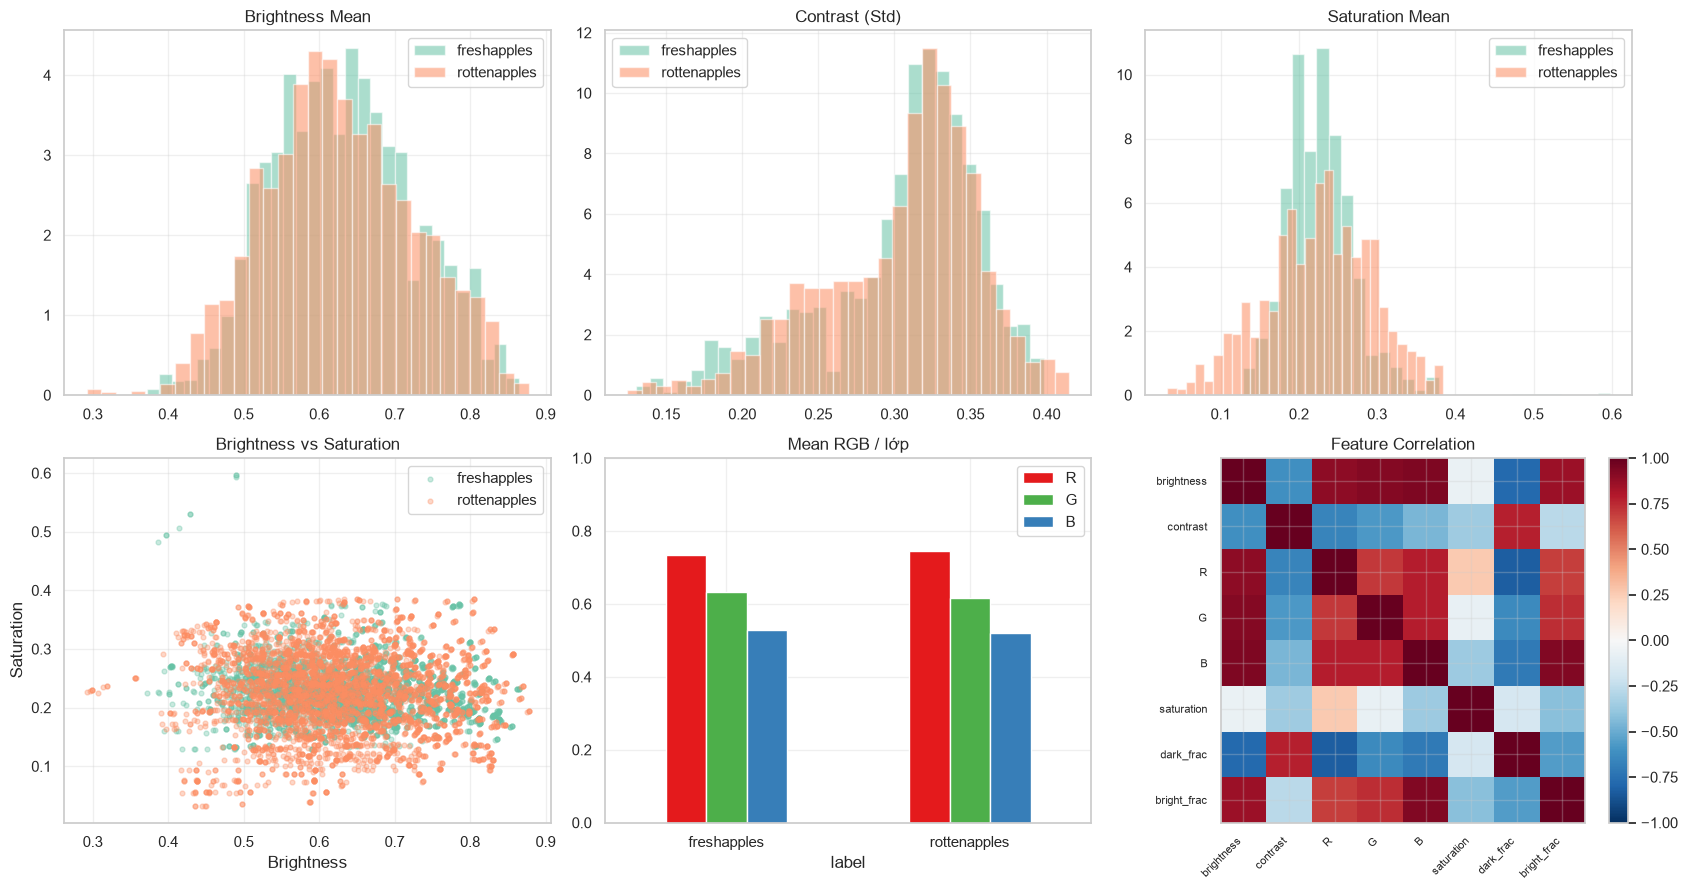

In [16]:
feat_cols = list(feats.columns)
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

for ax, col, t in zip(axes[0],
    ['brightness','contrast','saturation'],
    ['Brightness Mean','Contrast (Std)','Saturation Mean']):
    for lbl, grp in ok.groupby('label'):
        ax.hist(grp[col], bins=30, alpha=.55, label=lbl,
                color=COLORS.get(lbl,'#888'), density=True)
    ax.set_title(t); ax.legend()

for lbl, grp in ok.groupby('label'):
    axes[1,0].scatter(grp.brightness, grp.saturation, s=12, alpha=.35,
                      label=lbl, color=COLORS.get(lbl,'#888'))
axes[1,0].set_xlabel('Brightness'); axes[1,0].set_ylabel('Saturation')
axes[1,0].set_title('Brightness vs Saturation'); axes[1,0].legend()

rgb_mean = ok.groupby('label')[['R','G','B']].mean()
rgb_mean.plot.bar(ax=axes[1,1], color=['#e41a1c','#4daf4a','#377eb8'])
axes[1,1].set_title('Mean RGB / lớp'); axes[1,1].set_ylim(0,1)
axes[1,1].tick_params(axis='x', rotation=0)

corr = ok[feat_cols].corr()
im_ax = axes[1,2].imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
axes[1,2].set_xticks(range(len(feat_cols)))
axes[1,2].set_yticks(range(len(feat_cols)))
axes[1,2].set_xticklabels(feat_cols, rotation=45, ha='right', fontsize=8)
axes[1,2].set_yticklabels(feat_cols, fontsize=8)
axes[1,2].set_title('Feature Correlation')
fig.colorbar(im_ax, ax=axes[1,2], fraction=.046)

plt.tight_layout()
fig.savefig(OUTPUT_DIR/'pixel_analysis.png', bbox_inches='tight')
plt.show()

## 8. Ảnh mẫu ngẫu nhiên (12 ảnh / lớp)
Hiển thị ảnh thực tế để kiểm tra trực quan chất lượng dữ liệu.

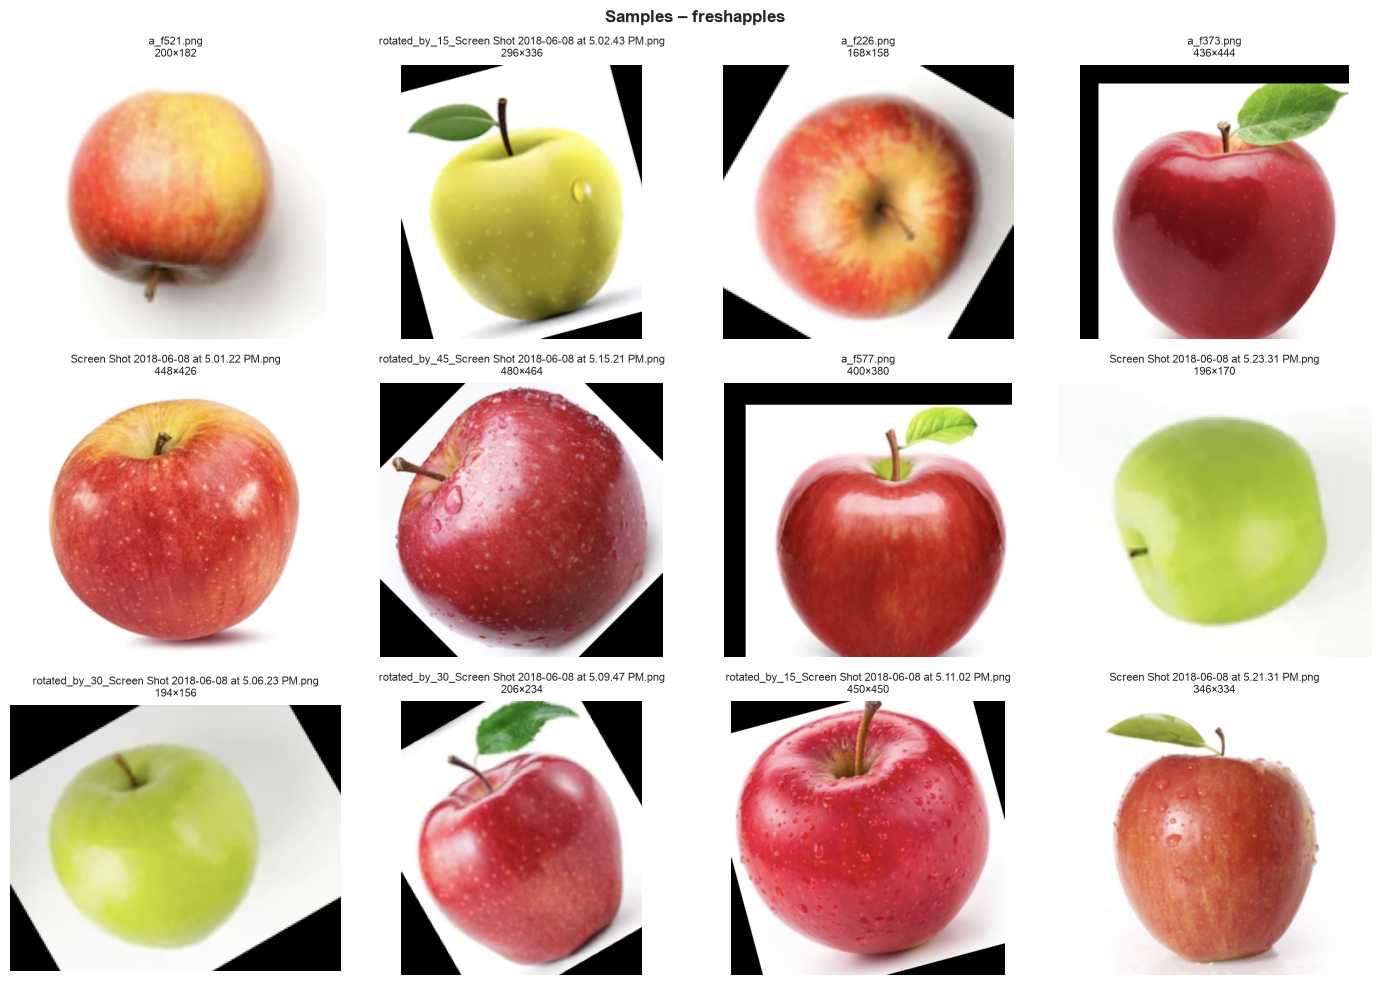

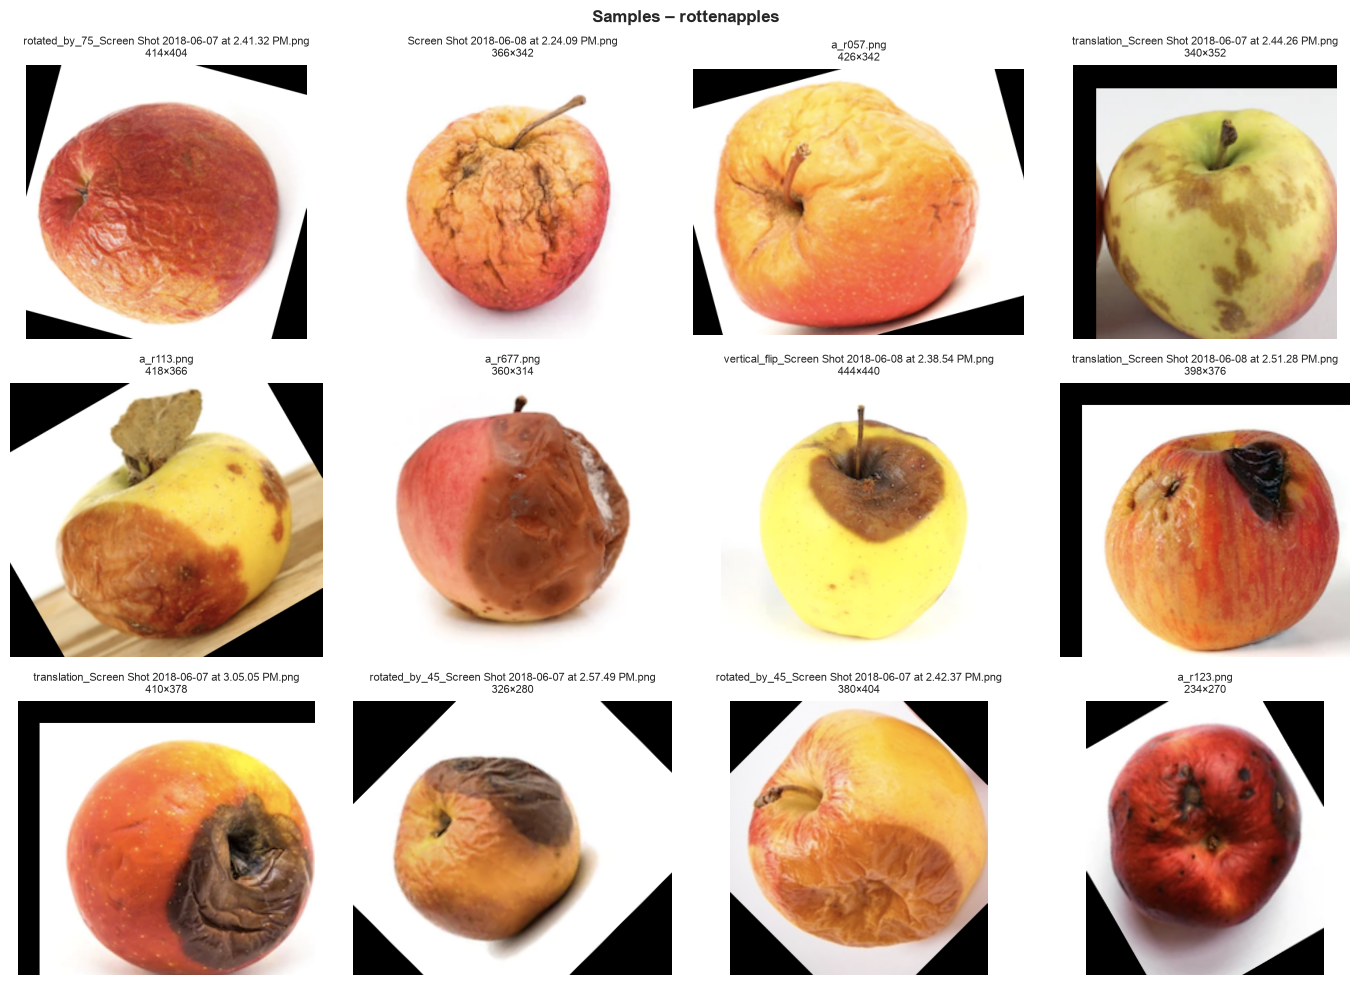


✅ Tất cả output đã lưu tại: eda_outputs/


In [17]:
rng = np.random.default_rng(231)
for lbl in sorted(ok.label.unique()):
    sub = ok[ok.label==lbl]
    idx = rng.choice(len(sub), min(12, len(sub)), replace=False)
    samples = sub.iloc[idx]
    fig, axes = plt.subplots(3, 4, figsize=(14, 10))
    for ax, (_, row) in zip(axes.ravel(), samples.iterrows()):
        with Image.open(row.path) as im:
            ax.imshow(im.convert('RGB'))
        ax.set_title(f'{row.filename}\n{int(row.w)}\u00d7{int(row.h)}', fontsize=8)
        ax.axis('off')
    for ax in axes.ravel()[len(samples):]: ax.axis('off')
    fig.suptitle(f'Samples \u2013 {lbl}', fontweight='bold')
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR/f'samples_{lbl}.png', bbox_inches='tight')
    plt.show()

print(f'\n\u2705 T\u1ea5t c\u1ea3 output \u0111\u00e3 l\u01b0u t\u1ea1i: {OUTPUT_DIR}/')